# Class project => learning how to manipulate the netCDF files

### extracting the necessary variables, plotting them, and writing them to a file

In [4]:
# import standard libraries
from IPython.display import IFrame
%matplotlib inline
import matplotlib.pyplot as plt
import getpass
import xarray as xr
import panel.widgets as pnw
import panel as pn
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import copernicusmarine
import datetime
import numpy as np
import sys
import os
from pylab import *
import csv
# setting-up the paths
#root_dir = r'/users/eleves-b/2026/david.holguin-gomez/.local/lib/python3.13/site-packages'
root_dir =os.getcwd()

# insert path where the local library is located
sys.path.insert(0,root_dir)

# import local library
#import wavetools.loaders.read_global_wave_ENPC as rdwv

# set the local data directory
datadir = os.path.join(root_dir,'data')
print(datadir)

# set out_dir to save the plots
outdir = os.path.join(root_dir,'output')
os.makedirs(outdir, exist_ok=True)
# To avoid warning messages
import warnings
warnings.filterwarnings('ignore')


/users/eleves-b/2026/david.holguin-gomez/Documents/Courses/Sea State/code/data


/users/eleves-b/2026/david.holguin-gomez/Documents/Courses/Sea State/copernicus/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# input the nc file name to examine
fname = 'cmems_mod_glo_wav_my_0.2deg_PT3H-i_1792168357110.nc'
ncfile = datadir + '/' + fname

DS = xr.open_dataset(ncfile)
DS

<xarray.Dataset> Size: 7MB
Dimensions:    (time: 87664, latitude: 2, longitude: 3)
Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
  * latitude   (latitude) float32 8B 47.8 48.0
  * longitude  (longitude) float32 12B -5.4 -5.2 -5.0
Data variables:
    VHM0       (time, latitude, longitude) float32 2MB ...
    VMDR       (time, latitude, longitude) float32 2MB ...
    VTM02      (time, latitude, longitude) float32 2MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Mean fields from global wave model MFWAM of Meteo-Fran...
    institution:       METEO-FRANCE
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_MULTIYEAR_WAV_001_032
    subset:datasetId:  cmems_mod_glo_wav_my_0.2deg_PT3H-i_202411
    subset:date:       2026-10-16T16:32:37.110Z

---
## Data Exploration

The Copernicus Marine Service provides several mechanisms for users to access and obtain its products: _[Copernicus Marine Client API - Open a dataset or read a dataframe remotely](https://help.marine.copernicus.eu/en/articles/8287609-copernicus-marine-client-api-open-a-dataset-or-read-a-dataframe-remotely#h_71eee6dbce)_ \
⚠️ For all of them, your Copernicus Marine credentials are **required**.

For our use case, we will access the data with the [copernicusmarine](https://help.marine.copernicus.eu/en/articles/7949409-copernicus-marine-client-introduction) toolbox.

To start, let's first open the **entire dataset**, that we'll store in the variable <code>DS</code>. \
We will see later how to select parameters (cf. [Plot Data](#Plot-Data)).

In [6]:
# General information about the data
DS.info

<bound method Dataset.info of <xarray.Dataset> Size: 7MB
Dimensions:    (time: 87664, latitude: 2, longitude: 3)
Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
  * latitude   (latitude) float32 8B 47.8 48.0
  * longitude  (longitude) float32 12B -5.4 -5.2 -5.0
Data variables:
    VHM0       (time, latitude, longitude) float32 2MB ...
    VMDR       (time, latitude, longitude) float32 2MB ...
    VTM02      (time, latitude, longitude) float32 2MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Mean fields from global wave model MFWAM of Meteo-Fran...
    institution:       METEO-FRANCE
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    s

In [7]:
# Get the full list of variables available in the dataset
DS.data_vars

Data variables:
    VHM0     (time, latitude, longitude) float32 2MB ...
    VMDR     (time, latitude, longitude) float32 2MB ...
    VTM02    (time, latitude, longitude) float32 2MB ...

In [8]:
# Get the list of dimensions
DS.coords

Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
  * latitude   (latitude) float32 8B 47.8 48.0
  * longitude  (longitude) float32 12B -5.4 -5.2 -5.0

In [9]:
# Get info on one specific variable (here Hm0)
DS.VHM0

<xarray.DataArray 'VHM0' (time: 87664, latitude: 2, longitude: 3)> Size: 2MB
[525984 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
  * latitude   (latitude) float32 8B 47.8 48.0
  * longitude  (longitude) float32 12B -5.4 -5.2 -5.0
Attributes:
    units:             m
    standard_name:     sea_surface_wave_significant_height
    long_name:         Spectral significant wave height (Hm0)
    WMO_code:          100
    cell_methods:      time:point area:mean
    type_of_analysis:  spectral analysis

In [10]:
DS.VMDR

<xarray.DataArray 'VMDR' (time: 87664, latitude: 2, longitude: 3)> Size: 2MB
[525984 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
  * latitude   (latitude) float32 8B 47.8 48.0
  * longitude  (longitude) float32 12B -5.4 -5.2 -5.0
Attributes:
    units:             degree
    standard_name:     sea_surface_wave_from_direction
    long_name:         Mean wave direction from (Mdir)
    WMO_code:          200
    cell_methods:      time:point area:mean
    type_of_analysis:  spectral analysis

In [11]:
DS.VTM02

<xarray.DataArray 'VTM02' (time: 87664, latitude: 2, longitude: 3)> Size: 2MB
[525984 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
  * latitude   (latitude) float32 8B 47.8 48.0
  * longitude  (longitude) float32 12B -5.4 -5.2 -5.0
Attributes:
    units:             s
    standard_name:     sea_surface_wave_mean_period_from_variance_spectral_de...
    long_name:         Spectral moments (0,2) wave period (Tm02)
    WMO_code:          221
    cell_methods:      time:point area:mean
    type_of_analysis:  spectral analysis

In [12]:
# Get info on specific dimensions 
DS.time

<xarray.DataArray 'time' (time: 87664)> Size: 701kB
array(['1996-01-01T00:00:00.000000000', '1996-01-01T03:00:00.000000000',
       '1996-01-01T06:00:00.000000000', ..., '2025-12-31T15:00:00.000000000',
       '2025-12-31T18:00:00.000000000', '2025-12-31T21:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
Attributes:
    standard_name:  time
    long_name:      Time
    axis:           T

In [13]:
# Define the target period of interest (here, the entire timeseries)
target_t_period=slice("1996-01-01","2025-12-31")
#target_t_period=slice("2023-01-01","2023-04-30")
location = (-5.49359, 47.96920)

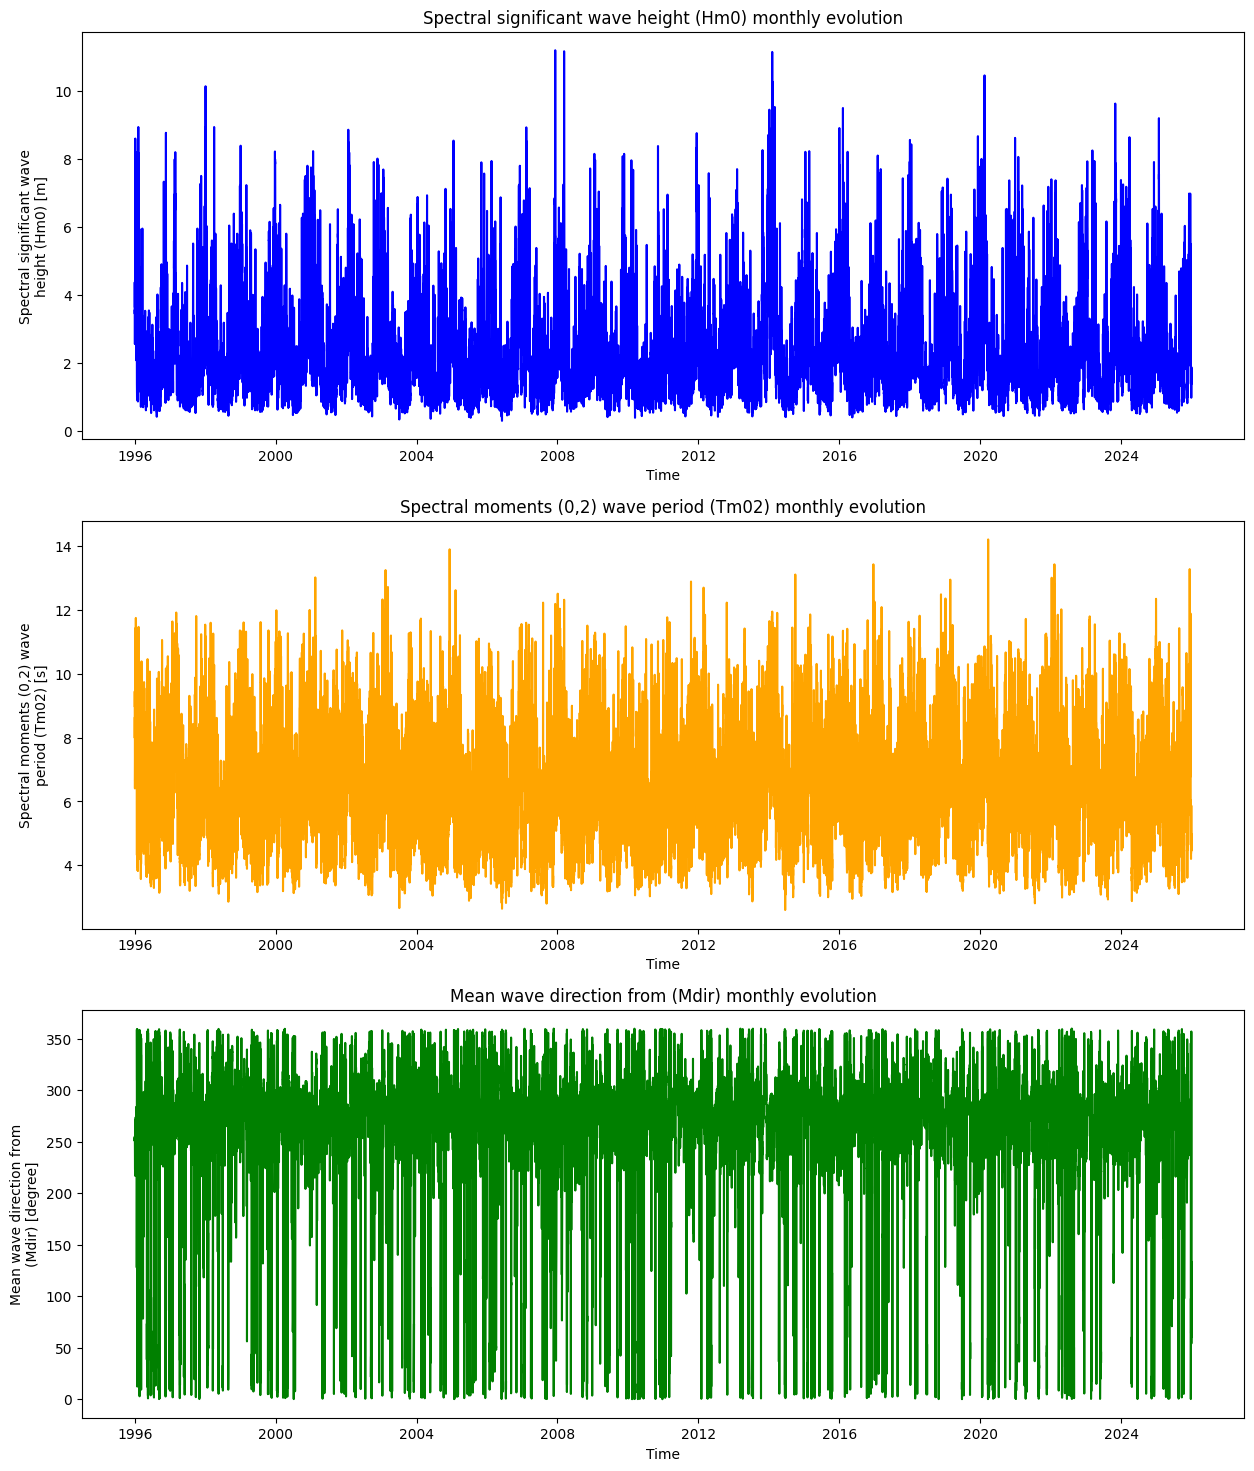

In [14]:
# Plotting the timeseries
point = DS.sel(latitude=location[0], longitude=location[1], method="nearest")

HM0 = point.VHM0.sel(time=target_t_period)
TM02 = point.VTM02.sel(time=target_t_period)
DIRM = point.VMDR.sel(time=target_t_period)
time = point.time.sel(time=target_t_period)
# AT HM0 FP DIR
plt.figure(figsize=(15,18))

plt.subplot(3, 1, 1)
HM0.plot(color = 'blue')
plt.title(f"{HM0.long_name} monthly evolution")

plt.subplot(3, 1, 2)
TM02.plot(color = 'orange')
plt.title(f"{TM02.long_name} monthly evolution")

plt.subplot(3, 1, 3)
DIRM.plot(color = 'green')
plt.title(f"{DIRM.long_name} monthly evolution")
plt.savefig(os.path.join(outdir, "wave_timeseries.pdf"), dpi=300)

In [15]:
# Save the data 
subset = DS[['time','VHM0','VTM02','VMDR']].sel(time = target_t_period).sel(latitude=location[0], longitude=location[1], method="nearest")
subset


<xarray.Dataset> Size: 2MB
Dimensions:    (time: 87664)
Coordinates:
  * time       (time) datetime64[ns] 701kB 1996-01-01 ... 2025-12-31T21:00:00
    latitude   float32 4B 47.8
    longitude  float32 4B -5.0
Data variables:
    VHM0       (time) float32 351kB ...
    VTM02      (time) float32 351kB ...
    VMDR       (time) float32 351kB ...
Attributes:
    Conventions:       CF-1.11
    title:             Mean fields from global wave model MFWAM of Meteo-Fran...
    institution:       METEO-FRANCE
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_MULTIYEAR_WAV_001_032
    subset:datasetId:  cmems_mod_glo_wav_my_0.2deg_PT3H-i_202411
    subset:date:       2026-10-16T16:32:37.110Z

In [16]:

a = np.squeeze(xr.DataArray(subset.variables['VHM0']))
b = np.squeeze(xr.DataArray(subset.variables['VTM02']))
c = np.squeeze(xr.DataArray(subset.variables['VMDR']))

# calculate time in seconds for the 3hr window
#at = np.arange(len(a))*3*60*60
#headertxt = 'Variables \n AT HM0 FP DIR'

# output the time step 
tt = np.squeeze(xr.DataArray(subset.variables['time']))
headertxt = 'Variables \n DATE HM0 FP DIR'

# make sure not to overwrite an existing file, and assign the same number to 
# the associated time file
def nextnonexistent(f):
    fnew = f
    tnew='time.txt'
    root, ext = os.path.splitext(f)
    i = 0
    while os.path.exists(fnew):
        i += 1
        fnew = '%s%i%s' % (root, i, ext)
        tnew = '%s%i%s' % ('time', i, ext)   
    return fnew,tnew

fout = 'output.txt'
fout,tout = nextnonexistent(fout)
with open(fout, 'a') as f:
    #f.write('# number of time steps \n'+str(len(a))+'\n')
    np.savetxt(f,np.vstack((a,b,c)).T,delimiter='   ', fmt='%s', newline='\n', header=headertxt)

np.savetxt(tout,np.vstack((time)),delimiter='   ', fmt='%s')

## Wave rose by direction and wave height

# This cell creates a stacked wave rose for the grid point nearest to `location`.

1. **Select the data:** retrieves `VMDR` (mean wave direction, indicating where waves come from) and `VHM0` (significant wave height) for the period specified by `target_t_period`.
2. **Prepare the table:** converts the data to a DataFrame and removes rows with missing values.
3. **Group the observations:** divides directions into 16 sectors of 22.5° and wave heights into five intervals: 0–1, 1–2, 2–4, 4–5, and ≥5 m.
4. **Calculate frequencies:** creates a cross-tabulation of percentages. Since normalization is global, all bars together represent 100% of the observations.
5. **Plot the wave rose:** displays each direction sector on a polar plot and stacks the wave-height intervals using different colors. North is at the top, and directions increase clockwise.

The title shows the coordinates of the selected grid point, and the legend identifies the wave-height intervals.

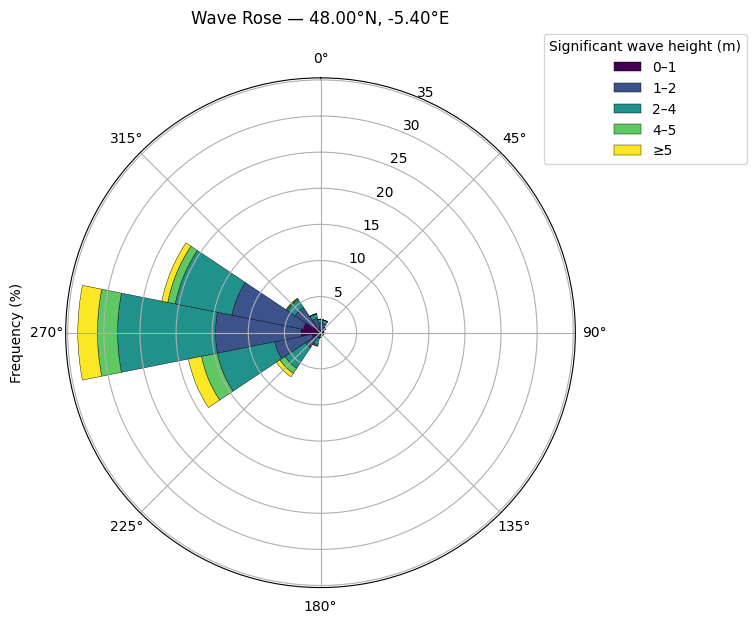

In [17]:
# Use (longitude, latitude) and select the nearest grid point
localisation = location

rose_site = DS.sel(
    longitude=localisation[0],
    latitude=localisation[1],
    method="nearest"
)[["VMDR", "VHM0"]].sel(time=target_t_period)

df_wave = (
    rose_site.to_dataframe()
    .reset_index()
    .dropna(subset=["VMDR", "VHM0"])
)

# Define 16 direction sectors and wave-height intervals
nb_sectors = 16
dir_bins = np.linspace(0, 360, nb_sectors + 1)
dir_labels = dir_bins[:-1]

df_wave["direction_sector"] = pd.cut(
    df_wave["VMDR"] % 360,
    bins=dir_bins,
    labels=dir_labels,
    include_lowest=True,
    right=False
)

wave_bins = [0, 1, 2, 4, 5, np.inf]
wave_labels = ["0–1", "1–2", "2–4", "4–5", "≥5"]

df_wave["wave_bin"] = pd.cut(
    df_wave["VHM0"],
    bins=wave_bins,
    labels=wave_labels,
    right=False
)

# Calculate each bin's percentage of all valid observations
freq_table = (
    pd.crosstab(
        df_wave["direction_sector"],
        df_wave["wave_bin"],
        normalize="all"
    )
    .reindex(index=dir_labels, columns=wave_labels, fill_value=0)
    * 100
)

# Plot the stacked wave rose
theta = np.deg2rad(dir_labels)
bar_width = np.deg2rad(360 / nb_sectors)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

bottom = np.zeros(nb_sectors)
colors_list = plt.cm.viridis(np.linspace(0, 1, len(wave_labels)))

for wave_label, color in zip(wave_labels, colors_list):
    values = freq_table[wave_label].to_numpy()
    ax.bar(
        theta,
        values,
        width=bar_width,
        bottom=bottom,
        color=color,
        edgecolor="black",
        linewidth=0.3,
        label=wave_label
    )
    bottom += values

ax.set_ylabel("Frequency (%)", labelpad=30)
ax.set_title(
    f"Wave Rose — {float(rose_site.latitude):.2f}°N, "
    f"{float(rose_site.longitude):.2f}°E",
    pad=20
)
ax.legend(title="Significant wave height (m)", loc="upper right",
          bbox_to_anchor=(1.35, 1.1))

plt.tight_layout()
plt.savefig(os.path.join(outdir, "wave_rose.pdf"), dpi=300)
plt.show()

In [18]:
# Select the nearest grid point; location is (longitude, latitude)
water_depth_m = 68.53  # Set to the local water depth in metres

site = DS.sel(
    longitude=location[0],
    latitude=location[1],
    method="nearest"
)[["VHM0", "VTM02", "VMDR"]].sel(time=target_t_period)

df_waves = site.to_dataframe().reset_index().dropna(
    subset=["VHM0", "VTM02", "VMDR"]
)

# Circular mean for directions (arithmetic means are inappropriate for angles)
def circular_mean_deg(direction):
    radians = np.deg2rad(direction.dropna())
    return np.rad2deg(np.arctan2(np.sin(radians).mean(),
                                 np.cos(radians).mean())) % 360

mean_hm0 = df_waves["VHM0"].mean()
mean_tm02 = df_waves["VTM02"].mean()
mean_direction = circular_mean_deg(df_waves["VMDR"])

print(f"Nearest grid point: latitude={float(site.latitude):.2f}, "
      f"longitude={float(site.longitude):.2f}")
print(f"Mean Hm0: {mean_hm0:.2f} m")
print(f"Mean Tm02: {mean_tm02:.2f} s")
print(f"Circular mean wave direction (from): {mean_direction:.1f}°")


Nearest grid point: latitude=48.00, longitude=-5.40
Mean Hm0: 2.42 m
Mean Tm02: 6.48 s
Circular mean wave direction (from): 283.8°


In [19]:
# Time series
#fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
#for ax, var, color in zip(
#    axes, ["VHM0", "VTM02", "VMDR"], ["blue", "orange", "green"]
#):
#    ax.plot(df_waves["time"], df_waves[var], color=color, linewidth=0.5)
#    ax.set_ylabel(f"{var} ({site[var].attrs.get('units', '')})")
#    ax.set_title(site[var].long_name)
#    ax.grid(True, alpha=0.3)
#axes[-1].set_xlabel("Time")
#plt.tight_layout()
#plt.savefig(os.path.join(outdir, "wave_timeseries.pdf"), dpi=300)
#plt.show()


Most common histogram bin: Hm0=1.62 m, Tm02=4.75 s (2184 observations)


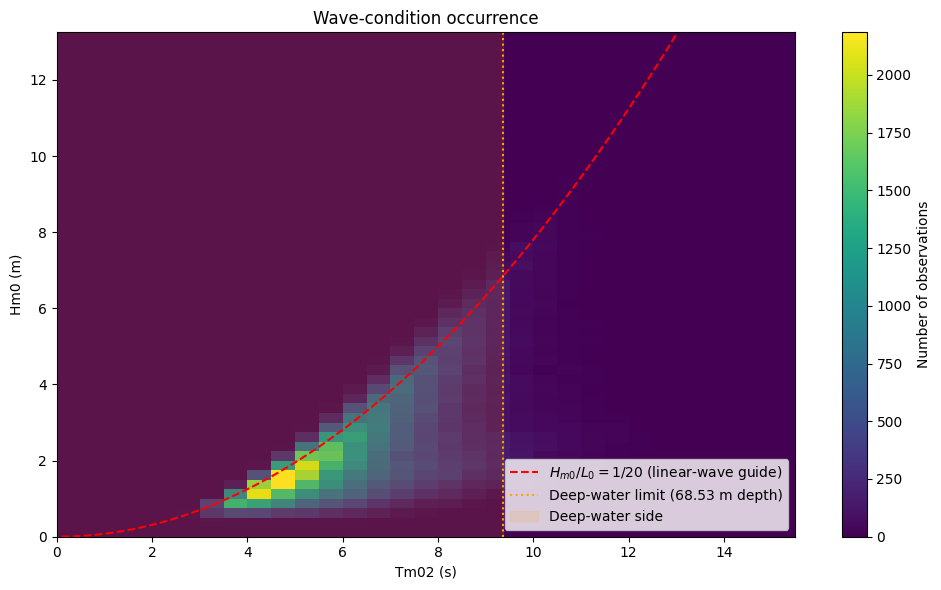

In [20]:

# Hm0–Tm02 occurrence histogram
h_edges = np.arange(0, max(6, np.ceil(df_waves["VHM0"].max()) + 0.5), 0.25)
t_edges = np.arange(0, np.ceil(df_waves["VTM02"].max()) + 1, 0.5)
counts, _, _ = np.histogram2d(
    df_waves["VTM02"], df_waves["VHM0"], bins=[t_edges, h_edges]
)
t_centres = (t_edges[:-1] + t_edges[1:]) / 2
h_centres = (h_edges[:-1] + h_edges[1:]) / 2

fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(t_edges, h_edges, counts.T, shading="auto", cmap="viridis")
fig.colorbar(mesh, ax=ax, label="Number of observations")
ax.set(xlabel="Tm02 (s)", ylabel="Hm0 (m)",
       title="Wave-condition occurrence")

mode_t, mode_h = np.unravel_index(np.argmax(counts), counts.shape)
print(f"Most common histogram bin: Hm0={h_centres[mode_h]:.2f} m, "
      f"Tm02={t_centres[mode_t]:.2f} s "
      f"({int(counts[mode_t, mode_h])} observations)")

# Approximate deep-water boundary and linear-wave steepness criterion.
# Deep water: depth > L0/2. Linear-wave guide: Hm0/L0 < 1/20.
g = 9.81
t_line = np.linspace(max(0.1, t_edges[0]), t_edges[-1], 300)
l0 = g * t_line**2 / (2 * np.pi)
ax.plot(t_line, l0 / 20, "r--", label=r"$H_{m0}/L_0=1/20$ (linear-wave guide)")

if water_depth_m is not None:
    t_deep_limit = np.sqrt(4 * np.pi * water_depth_m / g)
    ax.axvline(t_deep_limit, color="orange", linestyle=":",
               label=f"Deep-water limit ({water_depth_m:g} m depth)")
    ax.axvspan(t_edges[0], min(t_deep_limit, t_edges[-1]),
               color="orange", alpha=0.12, label="Deep-water side")
else:
    print("Set water_depth_m to a bathymetry value to show the deep-water limit.")

ax.set_ylim(0, h_edges[-1])
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(outdir, "wave_histogram.pdf"), dpi=300)
plt.show()


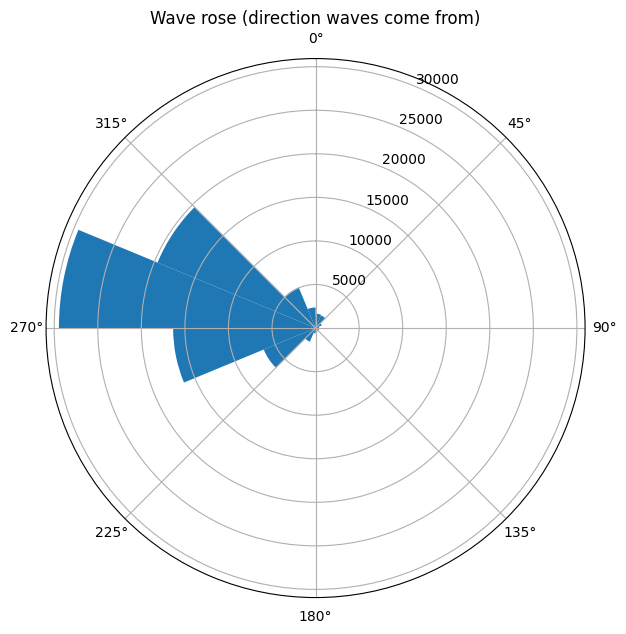

In [21]:

# Wave rose: directions are reported as directions waves come from
#direction_bins = np.arange(0, 361, 22.5)
#rose_counts, _ = np.histogram(df_waves["VMDR"] % 360, bins=direction_bins)
#theta = np.deg2rad((direction_bins[:-1] + direction_bins[1:]) / 2)

#fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
#ax.bar(theta, rose_counts, width=np.deg2rad(22.5), align="center")
#ax.set_theta_zero_location("N")
#ax.set_theta_direction(-1)
#ax.set_title("Wave rose (direction waves come from)")#
#plt.show()


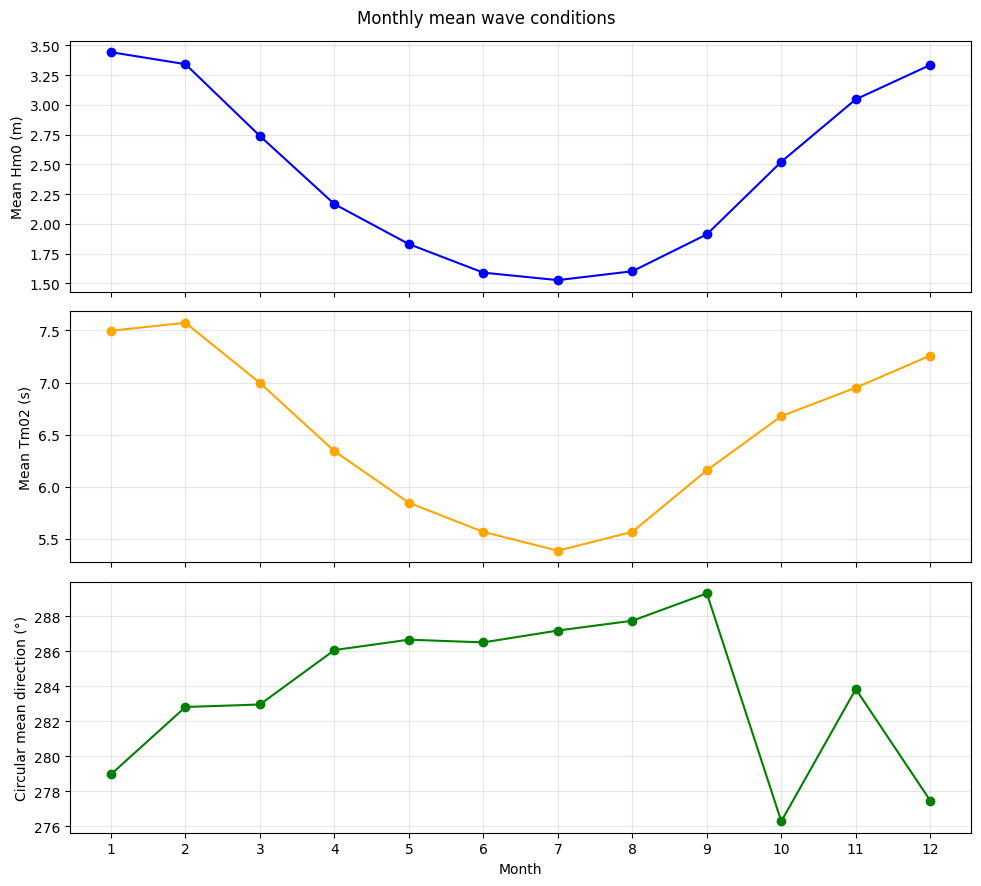

In [25]:

# Monthly climatology
df_waves["month"] = df_waves["time"].dt.month
monthly = df_waves.groupby("month").agg(
    Hm0=("VHM0", "mean"),
    Tm02=("VTM02", "mean"),
    direction=("VMDR", circular_mean_deg)
).reindex(range(1, 13))

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, col, color, ylabel in zip(
    axes,
    ["Hm0", "Tm02", "direction"],
    ["blue", "orange", "green"],
    ["Mean Hm0 (m)", "Mean Tm02 (s)", "Circular mean direction (°)"]
):
    ax.plot(monthly.index, monthly[col], marker="o", color=color)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axes[-1].set_xticks(range(1, 13))
axes[-1].set_xlabel("Month")
fig.suptitle("Monthly mean wave conditions")
plt.tight_layout()
plt.savefig(os.path.join(outdir, "wave_monthly_climatology.pdf"), dpi=300)
plt.show()

time
1996-01-01 00:00:00    3.66
1996-01-01 03:00:00    3.98
1996-01-01 06:00:00    4.13
1996-01-01 09:00:00    4.37
1996-01-01 12:00:00    4.07
Name: Hm0, dtype: float64
Annual Hm0 maxima:
time
1996-02-07 15:00:00     8.94
1997-02-25 00:00:00     8.20
1998-01-04 18:00:00    10.14
1999-01-03 09:00:00     8.39
2000-11-26 03:00:00     7.80
Name: Hm0, dtype: float64
               return value   lower ci   upper ci
return period                                    
1.0                    -inf        NaN   5.958267
2.0                8.790517   8.204764   9.489939
5.0               10.049868   9.085890  10.708463
10.0              10.549429   9.602005  10.984589
25.0              10.951826  10.117752  11.951687
50.0              11.142858  10.330278  13.221550
100.0             11.273203  10.448408  14.677686
250.0             11.385040  10.561082  17.039241
500.0             11.439659  10.629698  19.163372
1000.0            11.477319  10.723774  21.847553


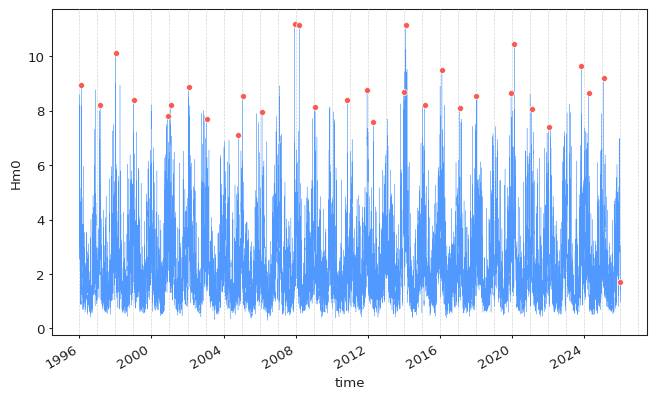

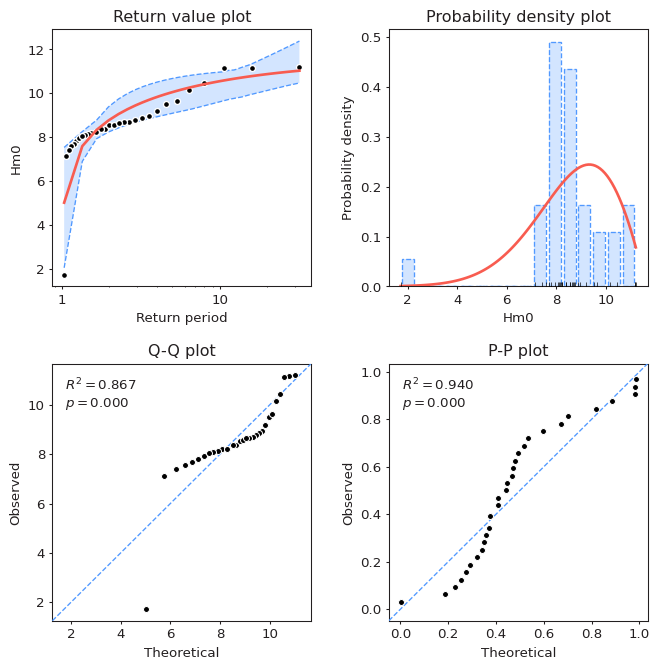

In [28]:
from pyextremes import EVA
# Convert the existing HM0 DataArray to a time series
hm0_series = HM0.to_series().sort_index().astype(float).dropna()
hm0_series.name = "Hm0"
hm0_series = hm0_series[~hm0_series.index.duplicated(keep="first")]

print(hm0_series.head())

# Extract annual maxima
model = EVA(hm0_series)
model.get_extremes(method="BM", block_size="365.2425D")

print("Annual Hm0 maxima:")
print(model.extremes.head())

model.plot_extremes()
plt.savefig(os.path.join(outdir, "annual_maxima.pdf"), dpi=300)

# Fit the model and estimate return levels
model.fit_model()

summary = model.get_summary(
    return_period=[1, 2, 5, 10, 25, 50, 100, 250, 500, 1000],
    alpha=0.95,
    n_samples=1000,
)
print(summary)

model.plot_diagnostic(alpha=0.95)
plt.savefig(os.path.join(outdir, "diagnostic_plot.pdf"), dpi=300)